<p style="align: center;"><img src="https://static.tildacdn.com/tild6636-3531-4239-b465-376364646465/Deep_Learning_School.png" width="400"></p>

# Глубокое обучение. Часть 2
# Домашнее задание по теме "Механизм внимания"

Это домашнее задание проходит в формате peer-review. Это означает, что его будут проверять ваши однокурсники. Поэтому пишите разборчивый код, добавляйте комментарии и пишите выводы после проделанной работы.

В этом задании вы будете решать задачу классификации математических задач по темам (многоклассовая классификация) с помощью Transformer.

В качестве датасета возьмем датасет математических задач по разным темам. Нам необходим следующий файл:

[Файл с классами](https://docs.google.com/spreadsheets/d/13YIbphbWc62sfa-bCh8MLQWKizaXbQK9/edit?usp=drive_link&ouid=104379615679964018037&rtpof=true&sd=true)

**Hint:** не перезаписывайте модели, которые вы получите на каждом из этапов этого дз. Они ещё понадобятся.

### Задание 1 (2 балла)

Напишите кастомный класс для модели трансформера для задачи классификации, использующей в качествке backbone какую-то из моделей huggingface.

Т.е. конструктор класса должен принимать на вход название модели и подгружать её из huggingface, а затем использовать в качестве backbone (достаточно возможности использовать в качестве backbone те модели, которые упомянуты в последующих пунктах)

In [1]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from typing import Union, List, Optional, Dict

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score

from transformers import AutoTokenizer, AutoModel, AutoConfig, get_linear_schedule_with_warmup, set_seed

## подготовка данных

In [2]:
set_seed(42)

In [3]:
df_ru = pd.read_excel('/content/data_problems.xlsx')
df_en = pd.read_excel('/content/data_problems_translated.xlsx')

In [4]:
df_ru.head()

,Unnamed: 0,Задача,Тема
0,0,Между девятью планетами Солнечной системы введ...,Графы
1,1,"В стране Цифра есть 9 городов с названиями 1, ...",Графы
2,2,"В государстве 100 городов, и из каждого из них...",Графы
3,3,"В классе 30 человек. Может ли быть так, что 9 ...",Графы
4,4,В городе Маленьком 15 телефонов. Можно ли их с...,Графы


In [5]:
df_en.head()

,Unnamed: 0,problem_text,topic
0,0,To prove that the sum of the numbers of the ex...,number_theory
1,1,( b) Will the statement of the previous challe...,number_theory
2,2,The quadratic three-member graph with the coef...,polynoms
3,3,Can you draw on the surface of Rubik's cube a ...,combinatorics
4,4,"Dima, who came from Vrunlandia, said that ther...",graphs


In [6]:
df_ru = df_ru.drop(columns=['Unnamed: 0'])
df_en = df_en.drop(columns=['Unnamed: 0'])

In [7]:
# для единообразия переименуем столбцы
df_ru = df_ru.rename(columns={
    'Задача': 'text',
    'Тема': 'label'
})

df_en = df_en.rename(columns={
    'problem_text': 'text',
    'topic': 'label'
})

In [8]:
print(df_ru.shape, df_en.shape)

(5273, 2) (5273, 2)


In [9]:
df_ru.head()

,text,label
0,Между девятью планетами Солнечной системы введ...,Графы
1,"В стране Цифра есть 9 городов с названиями 1, ...",Графы
2,"В государстве 100 городов, и из каждого из них...",Графы
3,"В классе 30 человек. Может ли быть так, что 9 ...",Графы
4,В городе Маленьком 15 телефонов. Можно ли их с...,Графы


In [10]:
df_en.head()

,text,label
0,To prove that the sum of the numbers of the ex...,number_theory
1,( b) Will the statement of the previous challe...,number_theory
2,The quadratic three-member graph with the coef...,polynoms
3,Can you draw on the surface of Rubik's cube a ...,combinatorics
4,"Dima, who came from Vrunlandia, said that ther...",graphs


отдельно для каждого датасета кодируем классы, так как они на разных языках, т.е для модели совершенно разные классы

In [11]:
label2id_ru = {label: id for id, label in enumerate(sorted(df_ru['label'].unique()))}
id2label_ru = {id: label for label, id in label2id_ru.items()}
df_ru['label_id'] = df_ru['label'].map(label2id_ru)
print(label2id_ru)
print('кол-вл классов ru:', len(label2id_ru))

label2id_en = {label: id for id, label in enumerate(sorted(df_en['label'].unique()))}
id2label_en = {id: label for label, id in label2id_en.items()}
df_en['label_id'] = df_en['label'].map(label2id_en)
print(label2id_en)
print('кол-вл классов en:', len(label2id_en))

{'Геометрия': 0, 'Графы': 1, 'Дирихле': 2, 'Инвариант': 3, 'Комбинаторика': 4, 'Многочлен': 5, 'Теория чисел': 6}
кол-вл классов ru: 7
{'combinatorics': 0, 'dirichlet': 1, 'geometry': 2, 'graphs': 3, 'invariant': 4, 'number_theory': 5, 'polynoms': 6}
кол-вл классов en: 7


In [12]:
train_df_ru, test_df_ru = train_test_split(df_ru, test_size=0.2, random_state=42,
                                           stratify=df_ru['label_id'])

train_df_ru, val_df_ru = train_test_split(train_df_ru, test_size=0.1, random_state=42,
                                          stratify=train_df_ru['label_id'])
print(train_df_ru.shape, test_df_ru.shape, val_df_ru.shape)

(3796, 3) (1055, 3) (422, 3)


In [13]:
train_df_en, test_df_en = train_test_split(df_en, test_size=0.2, random_state=42,
                                           stratify=df_en['label_id'])

train_df_en, val_df_en = train_test_split(train_df_en, test_size=0.1, random_state=42,
                                          stratify=train_df_en['label_id'])
print(train_df_en.shape, test_df_en.shape, val_df_en.shape)

(3796, 3) (1055, 3) (422, 3)


In [14]:
class MathTaskDataset(Dataset):
  def __init__(self, df, tokenizer, max_length=256):
    self.df = df.reset_index(drop=True)
    self.tokenizer = tokenizer
    self.max_len = max_length

  def __len__(self):
    return len(self.df)

  def __getitem__(self, index):
     row = self.df.iloc[index]
     text = str(row['text'])
     label = int(row['label_id'])

     encoding = self.tokenizer(
         text, truncation=True, padding='max_length', max_length=self.max_len, return_tensors='pt'
     )

     item = {
         'input_ids': encoding['input_ids'].squeeze(0),
         'attention_mask': encoding['attention_mask'].squeeze(0),
         'labels': torch.tensor(label, dtype=torch.long),
         'text': text
     }

     if 'token_type_ids' in encoding:
          item['token_type_ids'] = encoding['token_type_ids'].squeeze(0)

     return item

In [15]:
class TransformerClassificationModel(nn.Module):
    def __init__(
        self, base_transformer_model: Union[str, nn.Module], num_classes: int, dropout: float = 0.2
    ):
        super().__init__()
        if isinstance(base_transformer_model, str):
            self.config = AutoConfig.from_pretrained(base_transformer_model)
            self.backbone = AutoModel.from_pretrained(base_transformer_model,
                                                      output_attentions=True)
        else:
            self.backbone = base_transformer_model
            self.config = self.backbone.config

        hidden_size = self.config.hidden_size
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(hidden_size, num_classes)

    def forward(self, input_ids, attention_mask, token_type_ids=None, labels=None):
        backbone_outputs = self.backbone(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids,
            output_attentions=True
        )

        cls_embedding = backbone_outputs.last_hidden_state[:, 0, :]
        logits = self.classifier(self.dropout(cls_embedding))
        outputs ={
            'logits': logits,
            'attentions': backbone_outputs.attentions,
            'last_hidden_state': backbone_outputs.last_hidden_state
        }

        if labels is not None:
            loss_fn = nn.CrossEntropyLoss()
            loss = loss_fn(logits, labels)
            outputs['loss'] = loss

        return outputs

### Задание 2 (1 балл)

Напишите функцию заморозки backbone у модели (если необходимо, возвращайте из функции модель)

In [16]:
def freeze_backbone_function(model: TransformerClassificationModel):
    for param in model.backbone.parameters():
      param.requires_grad = False
    return model

In [17]:
def unfreeze_backbone_function(model: TransformerClassificationModel):
    for param in model.backbone.parameters():
      param.requires_grad = True
    return model

подсчет метрик

In [18]:
def compute_metrics(y_true, y_pred):
  return {
      'accuracy': accuracy_score(y_true, y_pred),
      'f1_macro': f1_score(y_true, y_pred, average='macro')
  }

напишем функцию для обучения и валидации в одну эпоху

In [19]:
def train_one_epoch(model, dataloader, device, optimizer, scheduler):
  model.train()
  total_loss = 0
  all_preds=[]
  all_labels = []

  for batch in dataloader:
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)
    token_type_ids = batch.get('token_type_ids')
    if token_type_ids is not None:
      token_type_ids = token_type_ids.to(device)

    optimizer.zero_grad()

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        token_type_ids=token_type_ids,
        labels=labels
    )

    loss = outputs['loss']
    loss.backward()
    optimizer.step()
    scheduler.step()

    total_loss += loss.item()
    preds = torch.argmax(outputs['logits'], dim=1)
    all_preds.extend(preds.detach().cpu().numpy())
    all_labels.extend(labels.detach().cpu().numpy())

  metrics = compute_metrics(all_labels, all_preds)
  metrics['loss'] = total_loss / len(dataloader)

  return metrics

In [20]:
@torch.no_grad()
def evaluate(model, dataloader, device):
  model.eval()
  total_loss = 0
  all_preds=[]
  all_labels = []

  for batch in dataloader:
    input_ids = batch['input_ids'].to(device)
    attention_mask = batch['attention_mask'].to(device)
    labels = batch['labels'].to(device)
    token_type_ids = batch.get('token_type_ids')
    if token_type_ids is not None:
      token_type_ids = token_type_ids.to(device)

    outputs = model(
        input_ids=input_ids,
        attention_mask=attention_mask,
        token_type_ids=token_type_ids,
        labels=labels
    )

    loss = outputs['loss']
    total_loss += loss.item()
    preds = torch.argmax(outputs['logits'], dim=1)
    all_preds.extend(preds.detach().cpu().numpy())
    all_labels.extend(labels.detach().cpu().numpy())

    metrics = compute_metrics(all_labels, all_preds)
    metrics["loss"] = total_loss / len(dataloader)

  return metrics

### Задание 3 (2 балла)

Напишите функцию, которая будет использована для тренировки (дообучения) трансформера (TransformerClassificationModel). Функция должна поддерживать обучение с замороженным и размороженным backbone.

In [21]:
import copy

def train_transformer(
    transformer_model,
    train_dataloader,
    val_dataloader,
    device,
    freeze_backbone=True,
    epochs=3,
    lr_head=1e-3,
    lr_backbone=2e-5
):
    model = copy.deepcopy(transformer_model)
    if freeze_backbone:
      model = freeze_backbone_function(model)
      optimizer = torch.optim.AdamW(
          filter(lambda p: p.requires_grad, model.parameters()),
          lr=lr_head
      )
    else:
      model = unfreeze_backbone_function(model)
      optimizer = torch.optim.AdamW([
          {'params': model.backbone.parameters(), 'lr': lr_backbone},
          {'params': model.classifier.parameters(), 'lr': lr_head}
      ])

    model.to(device)
    total_steps = epochs * len(train_dataloader)

    scheduler = get_linear_schedule_with_warmup(
        optimizer,
        num_warmup_steps=int(0.1 * total_steps),
        num_training_steps=total_steps
    )

    best_model_weights = copy.deepcopy(model.state_dict())
    best_val_f1 = -1

    history = {
        "train_loss": [],
        "train_acc": [],
        "train_f1": [],
        "val_loss": [],
        "val_acc": [],
        "val_f1": []
    }

    for epoch in range(epochs):
      train_metrics = train_one_epoch(model, train_dataloader, device, optimizer, scheduler)
      val_metrics = evaluate(model, val_dataloader, device)

      history["train_loss"].append(train_metrics["loss"])
      history["train_acc"].append(train_metrics["accuracy"])
      history["train_f1"].append(train_metrics["f1_macro"])

      history["val_loss"].append(val_metrics["loss"])
      history["val_acc"].append(val_metrics["accuracy"])
      history["val_f1"].append(val_metrics["f1_macro"])

      print(f"epoch {epoch + 1}/{epochs}")
      print(f"train loss={train_metrics['loss']:.4f}, acc={train_metrics['accuracy']:.4f}, f1={train_metrics['f1_macro']:.4f}")
      print(f"val   loss={val_metrics['loss']:.4f}, acc={val_metrics['accuracy']:.4f}, f1={val_metrics['f1_macro']:.4f}")
      print("=" * 60)

      if val_metrics["f1_macro"] > best_val_f1:
        best_val_f1 = val_metrics["f1_macro"]
        best_model_weights = copy.deepcopy(model.state_dict())

    model.load_state_dict(best_model_weights)
    return model, history

### Задание 4 (1 балл)

Проверьте вашу функцию из предыдущего пункта, дообучив двумя способами
*cointegrated/rubert-tiny2* из huggingface.

In [22]:
rubert_name = "cointegrated/rubert-tiny2"
rubert_tokenizer = AutoTokenizer.from_pretrained(rubert_name)

train_dataset_ru = MathTaskDataset(train_df_ru, rubert_tokenizer, max_length=256)
val_dataset_ru = MathTaskDataset(val_df_ru, rubert_tokenizer, max_length=256)
test_dataset_ru = MathTaskDataset(test_df_ru, rubert_tokenizer, max_length=256)

train_loader_ru = DataLoader(train_dataset_ru, batch_size=16, shuffle=True)
val_loader_ru = DataLoader(val_dataset_ru, batch_size=16, shuffle=False)
test_loader_ru = DataLoader(test_dataset_ru, batch_size=16, shuffle=False)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/693 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/401 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

обучение с замороженным backbone

In [23]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

rubert_tiny_transformer_model = TransformerClassificationModel(
    base_transformer_model=rubert_name,
    num_classes=len(label2id_ru)
)

rubert_tiny_finetuned_with_freezed_backbone, rubert_freeze_history = train_transformer(
    rubert_tiny_transformer_model,
    train_loader_ru,
    val_loader_ru,
    device=device,
    freeze_backbone=True,
    epochs=3
)

model.safetensors:   0%|          | 0.00/118M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/3
train loss=1.4431, acc=0.4642, f1=0.2454
val   loss=1.1787, acc=0.5427, f1=0.3499
epoch 2/3
train loss=1.1452, acc=0.5632, f1=0.3645
val   loss=1.1067, acc=0.5853, f1=0.4205
epoch 3/3
train loss=1.1098, acc=0.5756, f1=0.3975
val   loss=1.0958, acc=0.5972, f1=0.4472


Полное дообучение

In [24]:
rubert_tiny_transformer_model = TransformerClassificationModel(
    base_transformer_model=rubert_name,
    num_classes=len(label2id_ru)
)

rubert_tiny_full_finetuned, rubert_full_history = train_transformer(
    rubert_tiny_transformer_model,
    train_loader_ru,
    val_loader_ru,
    device=device,
    freeze_backbone=False,
    epochs=3
)

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/3
train loss=1.3411, acc=0.4950, f1=0.3080
val   loss=1.0842, acc=0.6066, f1=0.4693
epoch 2/3
train loss=1.0218, acc=0.5980, f1=0.4478
val   loss=1.0009, acc=0.6303, f1=0.4850
epoch 3/3
train loss=0.9311, acc=0.6317, f1=0.4984
val   loss=0.9849, acc=0.6327, f1=0.5002


In [25]:
rubert_freeze_test_metrics = evaluate(rubert_tiny_finetuned_with_freezed_backbone, test_loader_ru, device)
rubert_full_test_metrics = evaluate(rubert_tiny_full_finetuned, test_loader_ru, device)

print("rubert frozen:", rubert_freeze_test_metrics)
print("rubert full:", rubert_full_test_metrics)

rubert frozen: {'accuracy': 0.5725118483412323, 'f1_macro': 0.3719053717290923, 'loss': 1.1011269652482234}
rubert full: {'accuracy': 0.6180094786729858, 'f1_macro': 0.45400328799948336, 'loss': 0.9799718802625482}


### Задание 5 (1 балл)

Обучите *tbs17/MathBert* (с замороженным backbone и без заморозки), проанализируйте результаты. Сравните скоры с первым заданием. Получилось лучше или нет? Почему?

In [26]:
mathbert_name = "tbs17/MathBERT"
mathbert_tokenizer = AutoTokenizer.from_pretrained(mathbert_name)

train_dataset_en = MathTaskDataset(train_df_en, mathbert_tokenizer, max_length=256)
val_dataset_en = MathTaskDataset(val_df_en, mathbert_tokenizer, max_length=256)
test_dataset_en = MathTaskDataset(test_df_en, mathbert_tokenizer, max_length=256)

train_loader_en = DataLoader(train_dataset_en, batch_size=16, shuffle=True)
val_loader_en = DataLoader(val_dataset_en, batch_size=16, shuffle=False)
test_loader_en = DataLoader(test_dataset_en, batch_size=16, shuffle=False)

config.json:   0%|          | 0.00/569 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/28.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Обучение с замороженным backbone

In [27]:
mathbert_model = TransformerClassificationModel(
    base_transformer_model=mathbert_name,
    num_classes=len(label2id_en)
)

mathbert_frozen, mathbert_frozen_history = train_transformer(
    mathbert_model,
    train_loader_en,
    val_loader_en,
    device=device,
    freeze_backbone=True,
    epochs=3
)

pytorch_model.bin:   0%|          | 0.00/441M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/440M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: tbs17/MathBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/3
train loss=1.4411, acc=0.4673, f1=0.2824
val   loss=1.1971, acc=0.5450, f1=0.3397
epoch 2/3
train loss=1.1729, acc=0.5580, f1=0.3965
val   loss=1.1293, acc=0.5592, f1=0.3755
epoch 3/3
train loss=1.1353, acc=0.5743, f1=0.4179
val   loss=1.1241, acc=0.5640, f1=0.3758


Полное дообучение

In [28]:
mathbert_model = TransformerClassificationModel(
    base_transformer_model=mathbert_name,
    num_classes=len(label2id_en)
)

mathbert_full, mathbert_full_history = train_transformer(
    mathbert_model,
    train_loader_en,
    val_loader_en,
    device=device,
    freeze_backbone=False,
    epochs=3
)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: tbs17/MathBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


epoch 1/3
train loss=1.2783, acc=0.5387, f1=0.3767
val   loss=0.9951, acc=0.6256, f1=0.4947
epoch 2/3
train loss=0.8896, acc=0.6512, f1=0.5416
val   loss=1.0317, acc=0.5853, f1=0.4216
epoch 3/3
train loss=0.6652, acc=0.7279, f1=0.6482
val   loss=1.0503, acc=0.5758, f1=0.4765


In [29]:
mathbert_frozen_test_metrics = evaluate(mathbert_frozen, test_loader_en, device)
mathbert_full_test_metrics = evaluate(mathbert_full, test_loader_en, device)

print("MathBERT frozen:", mathbert_frozen_test_metrics)
print("MathBERT full:", mathbert_full_test_metrics)

MathBERT frozen: {'accuracy': 0.5582938388625592, 'f1_macro': 0.37261820339684826, 'loss': 1.1516626079877217}
MathBERT full: {'accuracy': 0.5933649289099526, 'f1_macro': 0.461233940193061, 'loss': 1.0361112726457191}


In [30]:
results = pd.DataFrame([
    {
        "model": "rubert_tiny2_frozen",
        "accuracy": rubert_freeze_test_metrics["accuracy"],
        "f1_macro": rubert_freeze_test_metrics["f1_macro"]
    },
    {
        "model": "rubert_tiny2_full",
        "accuracy": rubert_full_test_metrics["accuracy"],
        "f1_macro": rubert_full_test_metrics["f1_macro"]
    },
    {
        "model": "MathBERT_frozen",
        "accuracy": mathbert_frozen_test_metrics["accuracy"],
        "f1_macro": mathbert_frozen_test_metrics["f1_macro"]
    },
    {
        "model": "MathBERT_full",
        "accuracy": mathbert_full_test_metrics["accuracy"],
        "f1_macro": mathbert_full_test_metrics["f1_macro"]
    }
])

results.sort_values("f1_macro", ascending=False)

,model,accuracy,f1_macro
3,MathBERT_full,0.593365,0.461234
1,rubert_tiny2_full,0.618009,0.454003
2,MathBERT_frozen,0.558294,0.372618
0,rubert_tiny2_frozen,0.572512,0.371905


полное дообучение без заморозки backbone лучше у обеих моделей. мы это можем видеть в выводе:

| # | model | accuracy | f1_macro |
|---|---------------|----------|----------|
| 3 | MathBERT_full | 0.593365 | 0.461234 |
| 1 | rubert_tiny2_full | 0.618009 | 0.454003 |
| 2 | MathBERT_frozen | 0.558294 | 0.372618 |
| 0 | rubert_tiny2_frozen | 0.572512 | 0.371905 |

а значит для этой задачи полезнее всего адаптировать внутренние представления backbone. также заметим, что rubert, обученная на русском датасете, показывает лучшие метрики accuracy (но не f1 macro), чем обученная на английском датасете MathBERT, поэтому сравнение не совсем честное, если перевод некорректен



### Задание 6 (1 балл)

Напишите функцию для отрисовки карт внимания первого слоя для моделей из задания

In [31]:
def draw_first_layer_attention_maps(
    attention_head_ids: List[int],
    text: str,
    model: TransformerClassificationModel,
    tokenizer,
    device,
    max_length: int = 128
):
    model.eval()

    encoding = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        padding="max_length",
        max_length=max_length
    )

    input_ids = encoding["input_ids"].to(device)
    attention_mask = encoding["attention_mask"].to(device)

    token_type_ids = encoding.get("token_type_ids")
    if token_type_ids is not None:
        token_type_ids = token_type_ids.to(device)

    with torch.no_grad():
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )

    attentions = outputs["attentions"]
    first_layer_attention = attentions[0][0].cpu().numpy()

    tokens = tokenizer.convert_ids_to_tokens(input_ids[0])
    valid_len = int(attention_mask[0].sum().item())
    tokens = tokens[:valid_len]

    for head_id in attention_head_ids:
        attn_map = first_layer_attention[head_id][:valid_len, :valid_len]

        plt.figure(figsize=(8, 6))
        plt.imshow(attn_map)
        plt.colorbar()
        plt.title(f"First layer attention, head {head_id}")
        plt.xticks(range(valid_len), tokens, rotation=90)
        plt.yticks(range(valid_len), tokens)
        plt.tight_layout()
        plt.show()

### Задание 7 (1 балл)

Проведите инференс для всех моделей **ДО ДООБУЧЕНИЯ** на 2-3 текстах из датасета. Посмотрите на головы Attention первого слоя в каждой модели на выбранных текстах (отрисуйте их отдельно).

Попробуйте их проинтерпретировать. Какие связи улавливают карты внимания? (если в модели много голов Attention, то проинтерпретируйте наиболее интересные)

для ruBERT

Loading weights:   0%|          | 0/55 [00:00<?, ?it/s]

BertModel LOAD REPORT from: cointegrated/rubert-tiny2
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


текст 1:
Пусть a, b, c – стороны треугольника, p – его
полупериметр, а r и R – радиусы вписанной и описанной
окружностей соответственно. Составьте уравнение с коэффициентами, зависящими от p, r, R, корнями которого являются числа a, b, c. Докажите равенство



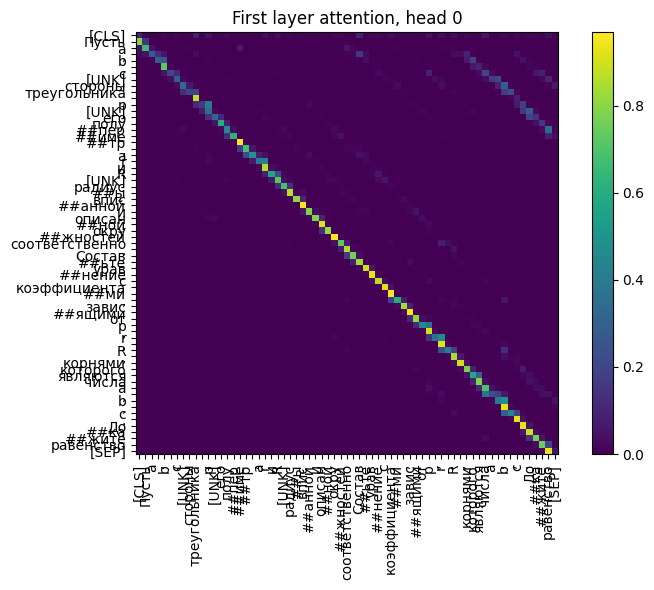

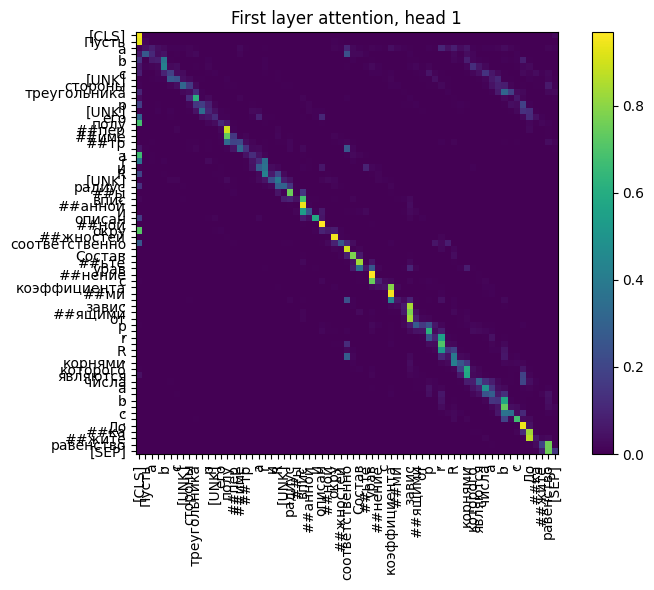

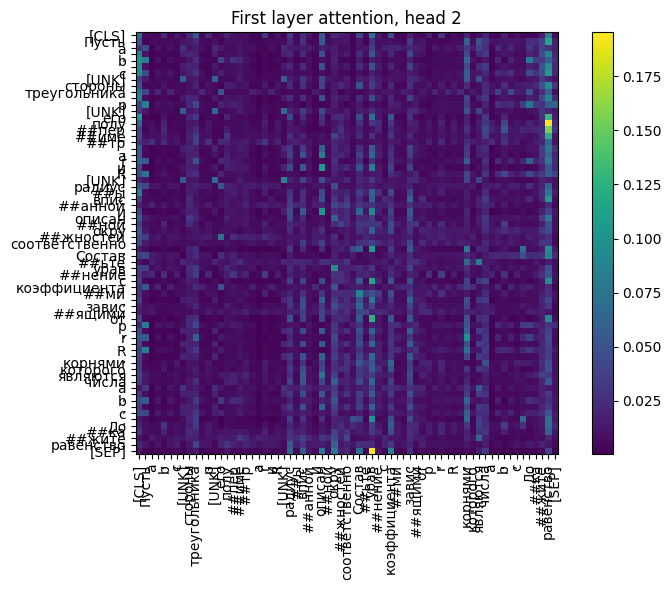

текст 2:
Сколько существует способов разрезать выпуклый (n+2)-угольник диагоналями на треугольники?


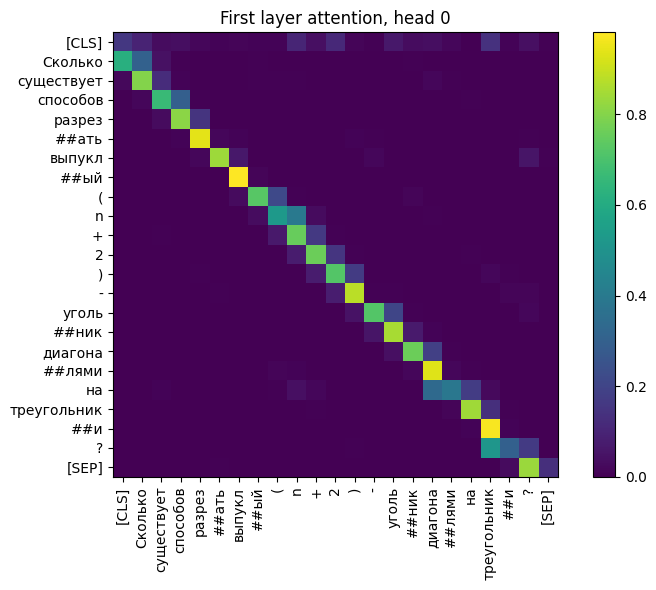

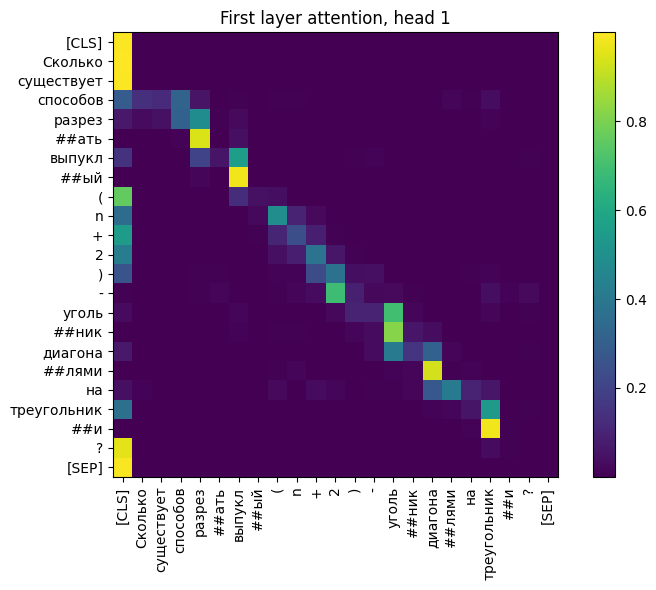

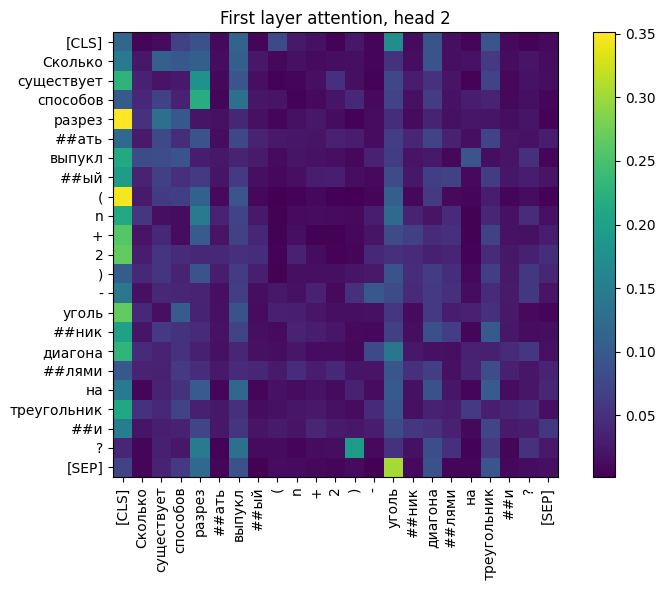

текст 3:
С помощью признака делимости Паскаля (см. задачу 60815) установите признаки делимости на числа 3, 9, 6, 8, 12, 15, 11, 7, 27, 37. 


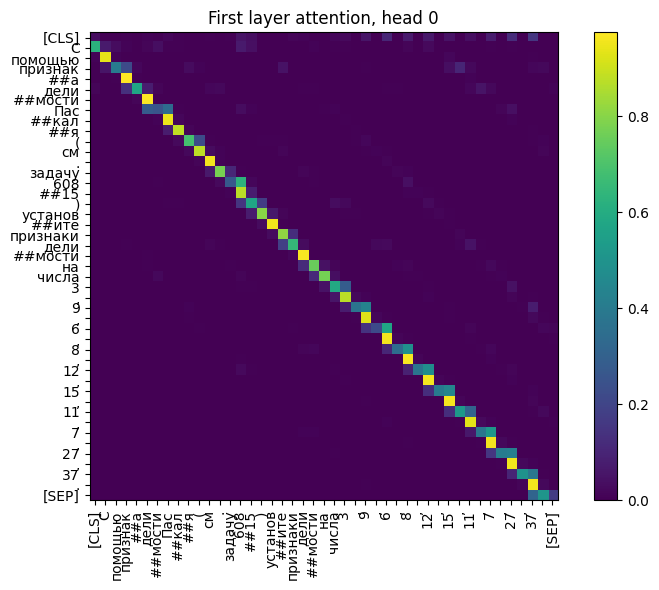

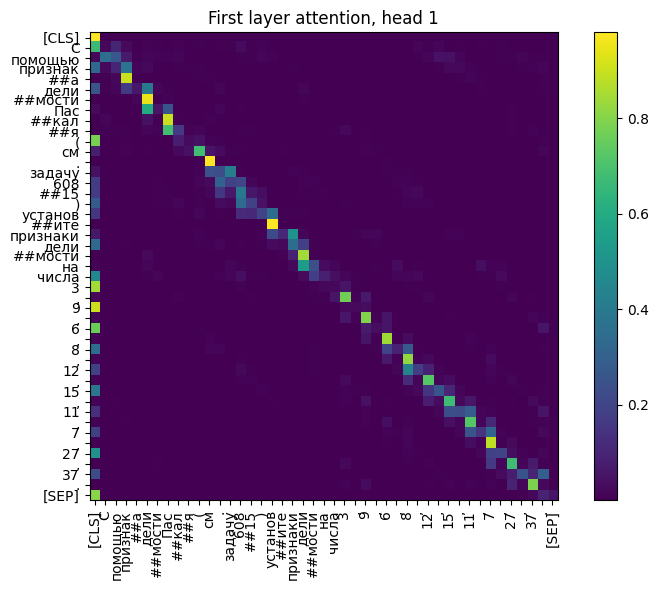

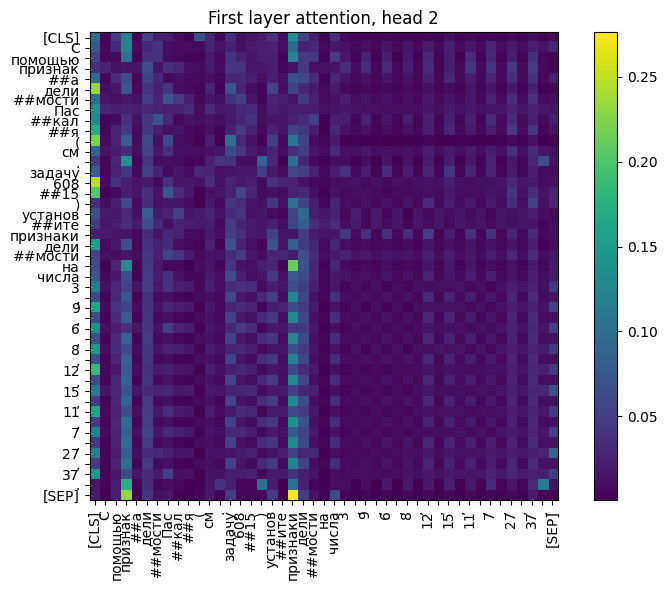

In [32]:
rubert_base_model = TransformerClassificationModel(
    base_transformer_model=rubert_name,
    num_classes=len(label2id_ru)
).to(device)

sample_texts_ru = [
    test_df_ru.iloc[0]["text"],
    test_df_ru.iloc[1]["text"],
    test_df_ru.iloc[2]["text"]
]

for i, text in enumerate(sample_texts_ru, 1):
    print(f"текст {i}:")
    print(text)
    draw_first_layer_attention_maps(
        attention_head_ids=[0, 1, 2],
        text=text,
        model=rubert_base_model,
        tokenizer=rubert_tokenizer,
        device=device
    )

видно, что в первом слое первая карта почти полностью диагональна, т.е. токены смотрят сами на себя либо на соседей, но не видят дальних связей, на которые стоит обратить внимание

вторая карта больше сконцентрирована на служебные токены. вероятно она помогает агрегировать инфу о всем тексте через позиции начала и конца предложения

третья голова выглядит рассеянно, значит токены видят глобально и имеют дальние связи

для MathBERT

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: tbs17/MathBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
bert.embeddings.position_ids               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


текст 1:
What is the relationship between the degradation of a rational number into a chaindrum and the Euclid algorithm?


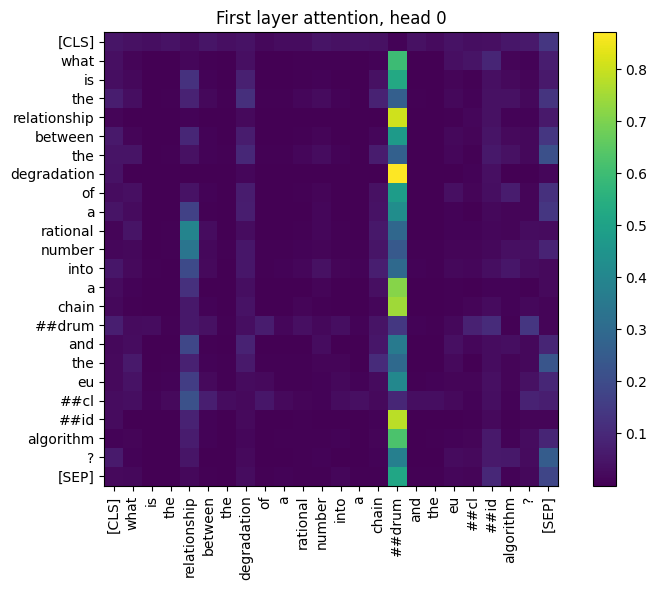

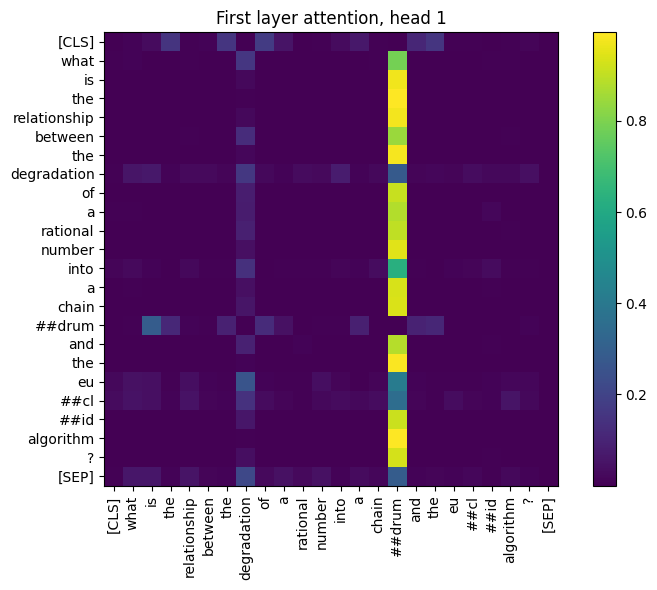

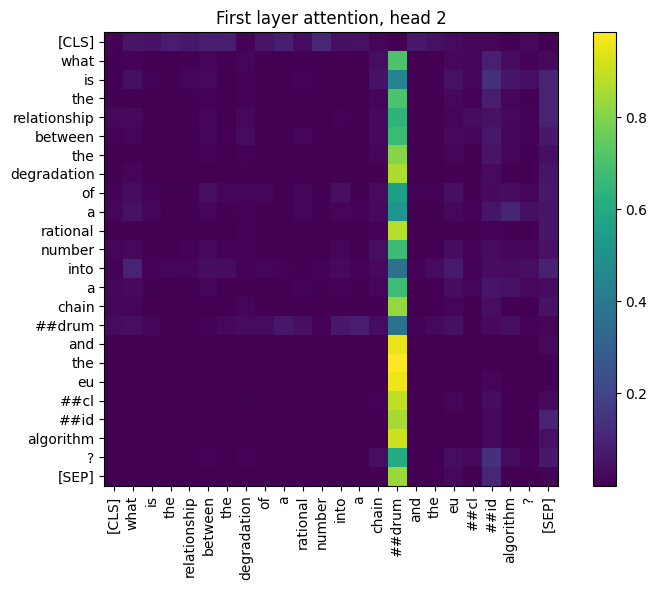

текст 2:
Two circles intersect at K and C points. Their centres are situated one side of the line containing the KC segments. The A and B points lie on different circles. A straight section containing the AK segment concerns one circle at K point. A straight section containing the BK segment touches the other circle also at K point. It is known that AK = 2, BK =, and tg\AKB = -. Find the area of the ABC triangle.


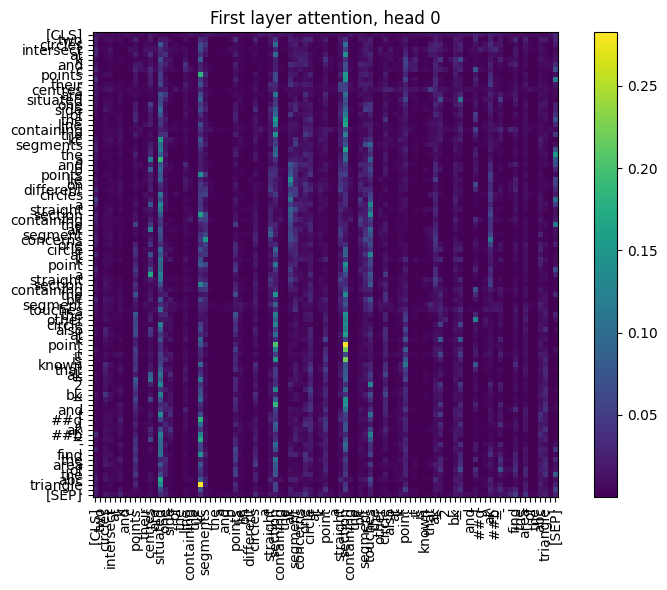

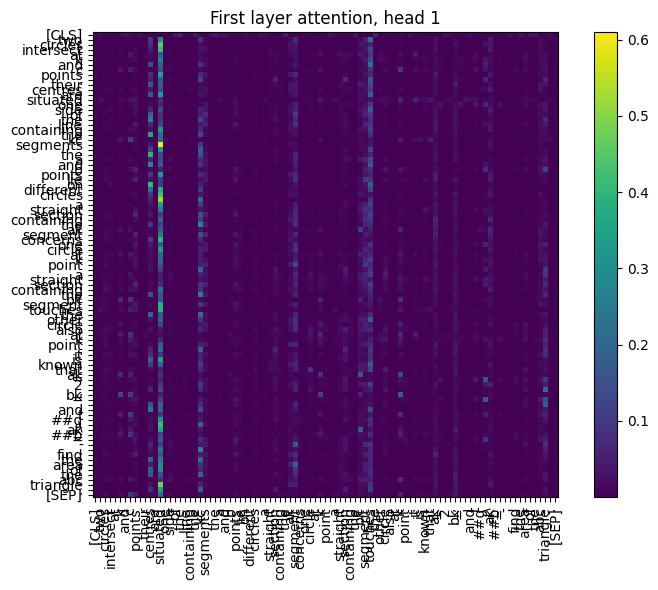

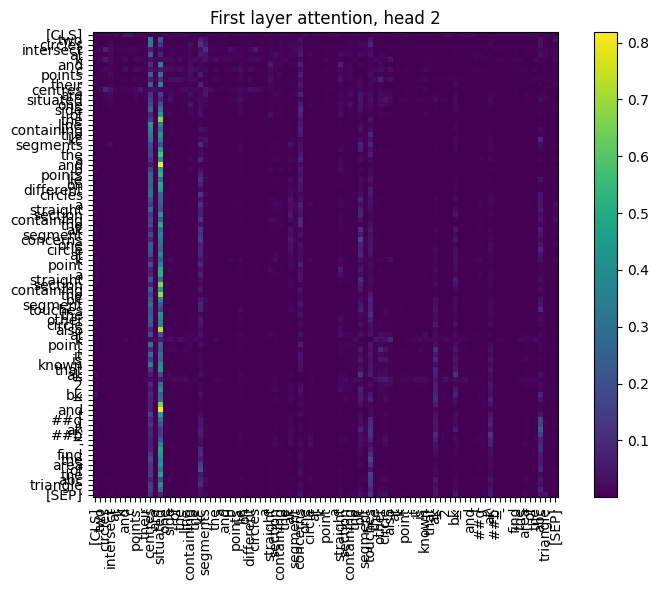

текст 3:
In Chicago, there are 36 criminal gangs, some of which are hostile to each other. Each gangster is in multiple gangs, and every two gangsters are in different gangs. It's known that no gangster is in two gangs, and it turns out that every gang that doesn't belong to a gangster is in conflict with some gang that this gangster is in. What's the largest number of gangsters in Chicago?


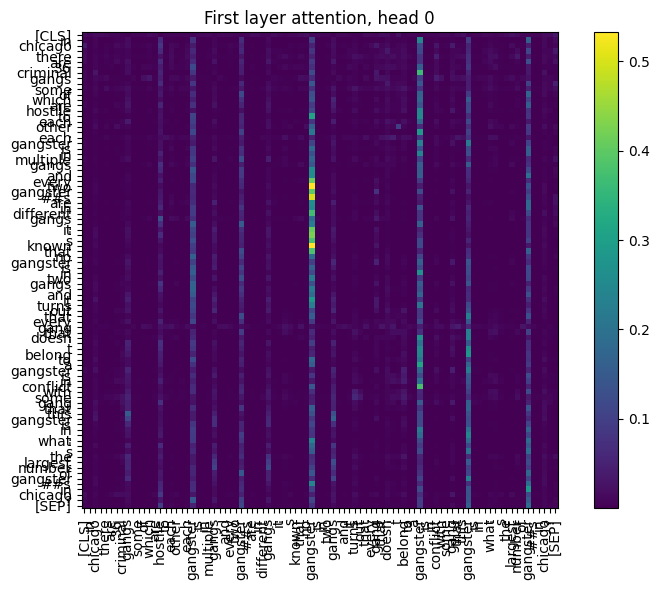

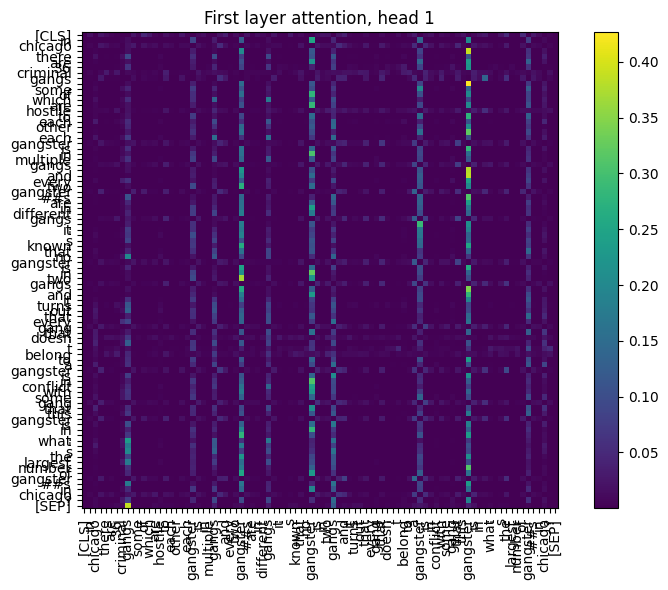

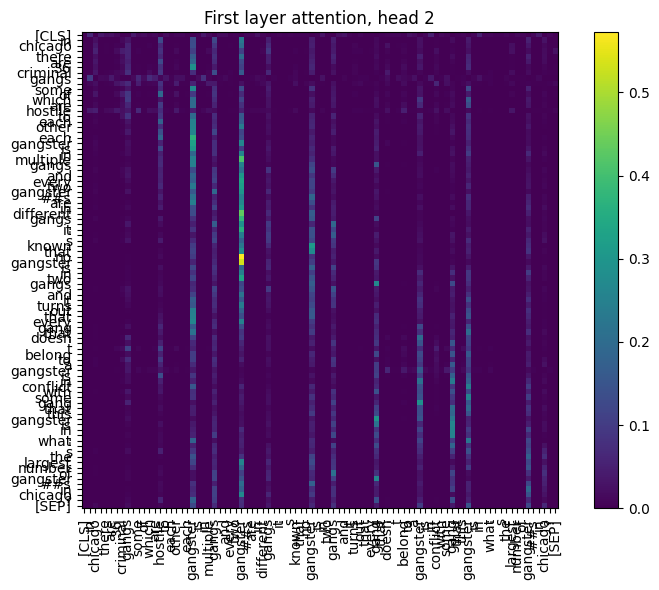

In [33]:
mathbert_base_model = TransformerClassificationModel(
    base_transformer_model=mathbert_name,
    num_classes=len(label2id_en)
).to(device)

sample_texts_en = [
    test_df_en.iloc[0]["text"],
    test_df_en.iloc[1]["text"],
    test_df_en.iloc[2]["text"]
]

for i, text in enumerate(sample_texts_en, 1):
    print(f"текст {i}:")
    print(text)
    draw_first_layer_attention_maps(
        attention_head_ids=[0, 1, 2],
        text=text,
        model=mathbert_base_model,
        tokenizer=mathbert_tokenizer,
        device=device
    )

у матберта же мы видим, что все головы сконцентрированы на одном центральном токене (вероятно потому, что руберт более общий, а матберт ориентирован на математические формулировки)

в первой голове первого слоя все токены имеют опору на одном токене, они выстраивают на карте вертикальную прямую, которая означает, что первая голова агрегирует инфу о последовательности через выделение опорного токена

во второй голове все токены еще сильнее обращают внимание на опорный токен

голова 3 так же обращает внимание на центральный токен, но ее распределение выглядит менее жестким, чем у головы 2, а значит эта голова учитывает и дополнительные связи внутри текста, а не в основном на от токен

### Задание 8 (1 балл)

Сделайте то же самое для дообученных моделей. Изменились ли карты внимания и связи, которые они улавливают? Почему?

ruBERT

текст 1:
Пусть a, b, c – стороны треугольника, p – его
полупериметр, а r и R – радиусы вписанной и описанной
окружностей соответственно. Составьте уравнение с коэффициентами, зависящими от p, r, R, корнями которого являются числа a, b, c. Докажите равенство



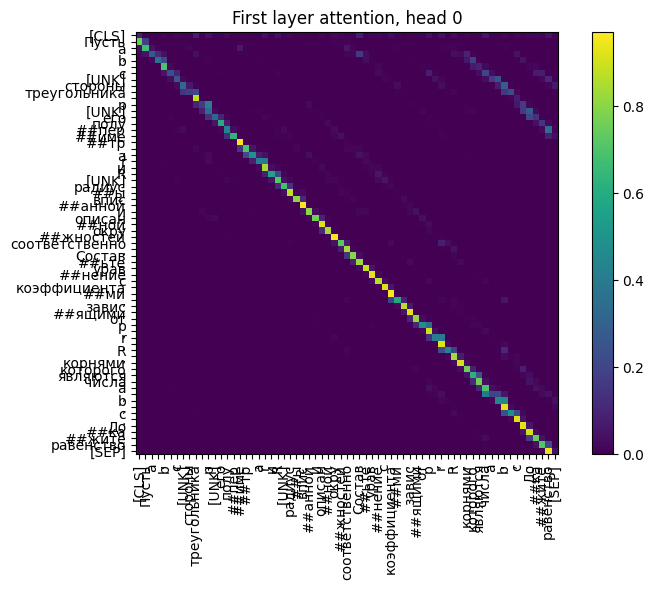

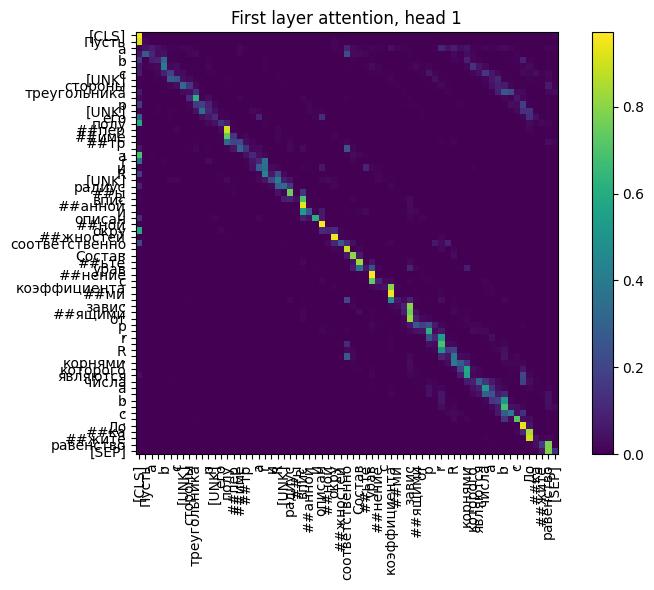

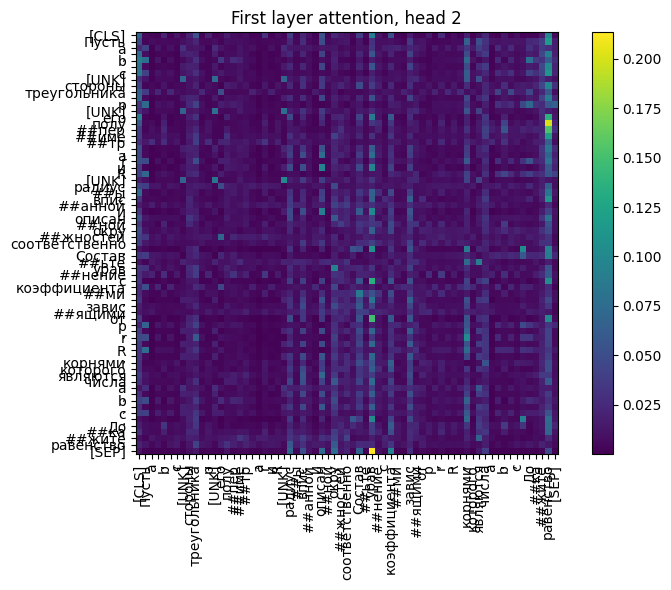

текст 2:
Сколько существует способов разрезать выпуклый (n+2)-угольник диагоналями на треугольники?


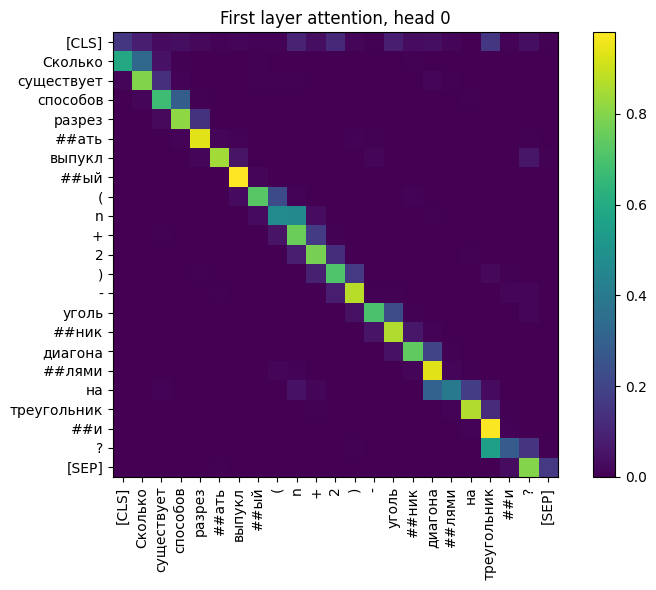

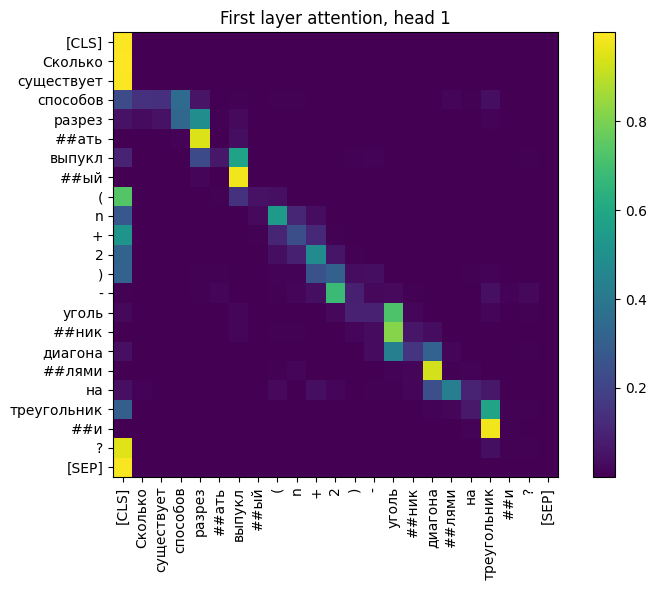

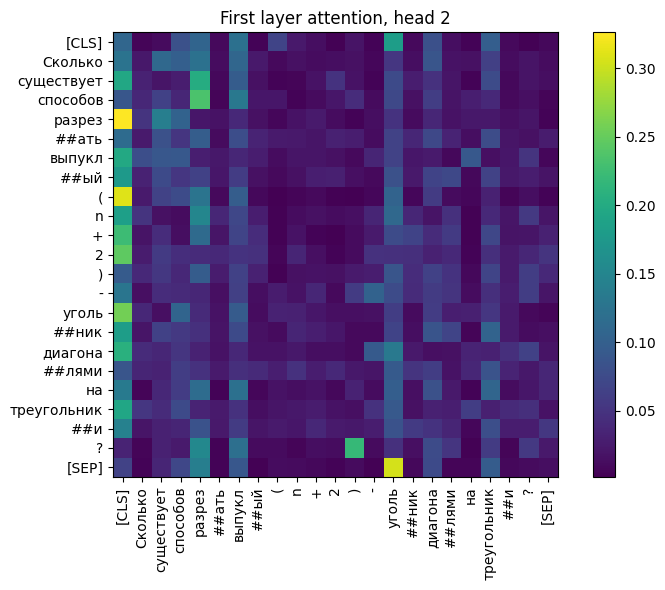

текст 3:
С помощью признака делимости Паскаля (см. задачу 60815) установите признаки делимости на числа 3, 9, 6, 8, 12, 15, 11, 7, 27, 37. 


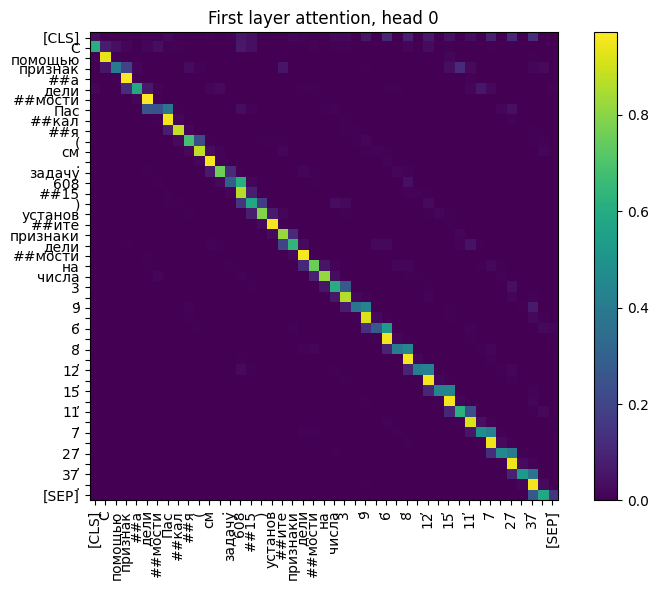

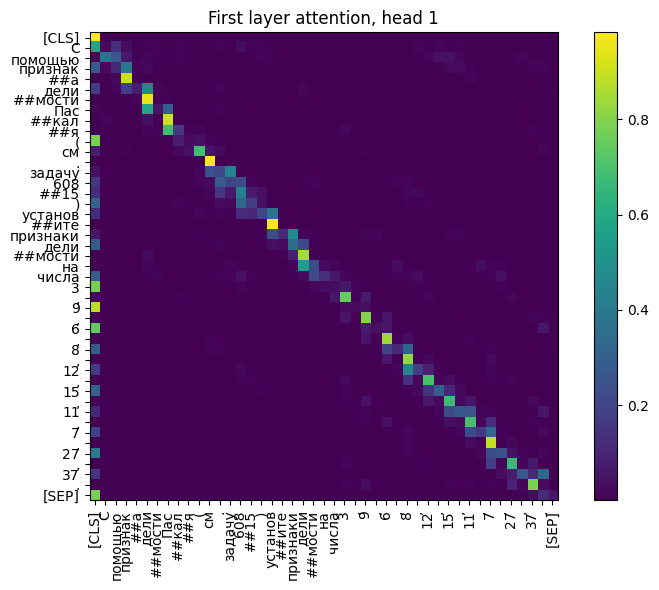

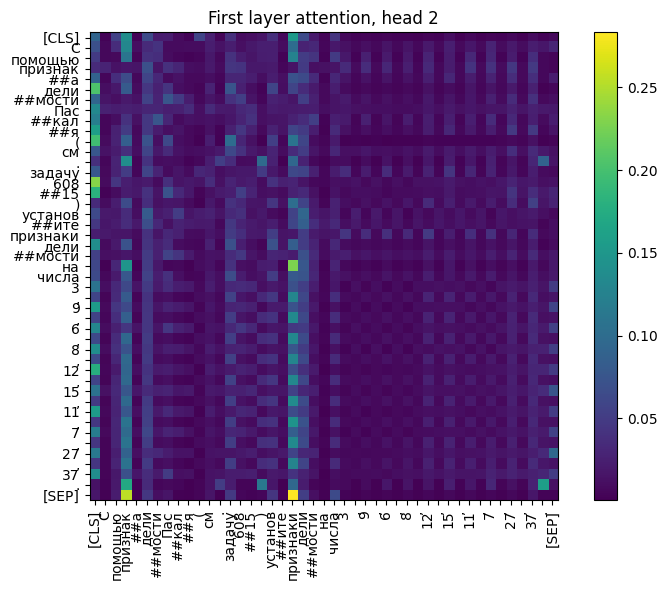

In [34]:
for i, text in enumerate(sample_texts_ru, 1):
    print(f"текст {i}:")
    print(text)
    draw_first_layer_attention_maps(
        attention_head_ids=[0, 1, 2],
        text=text,
        model=rubert_tiny_full_finetuned,
        tokenizer=rubert_tokenizer,
        device=device
    )

голова1.она по-прежнему в основном фиксирует локальные зависимости между соседними токенами и частями слов. Следовательно, дообучение практически не изменил ее базовую функцию .

голова 1 после дообучения, как и до него, активно использует специальные токены

голова 2 после дообучения сохраняет более распределённый характер внимания.

головы радикально не изменились. а это значит, дообучение не создало новую стратегию внимания, а скорее сохранило и адаптировало уже существующую.

MathBERT

текст 1:
What is the relationship between the degradation of a rational number into a chaindrum and the Euclid algorithm?


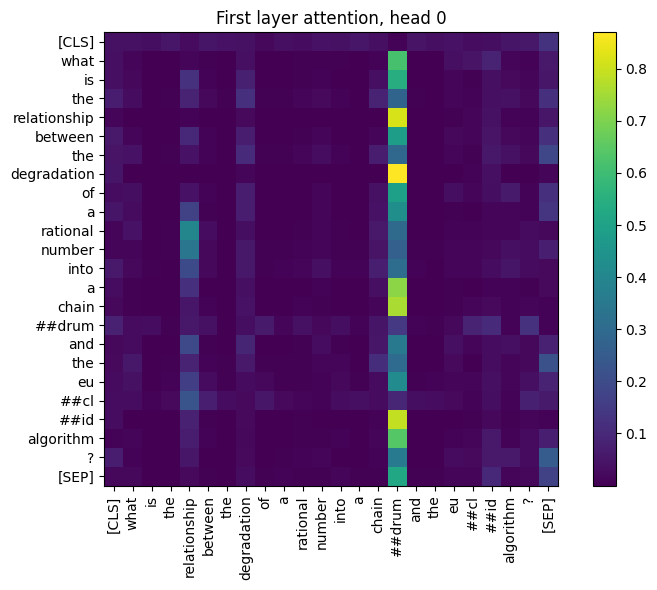

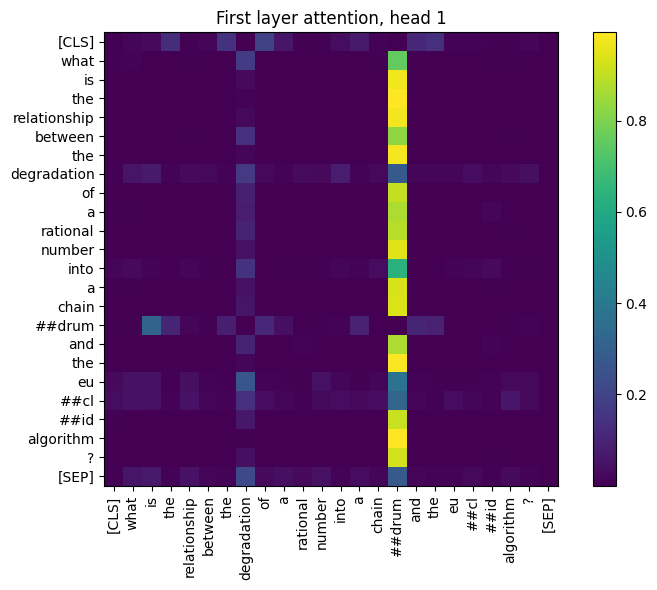

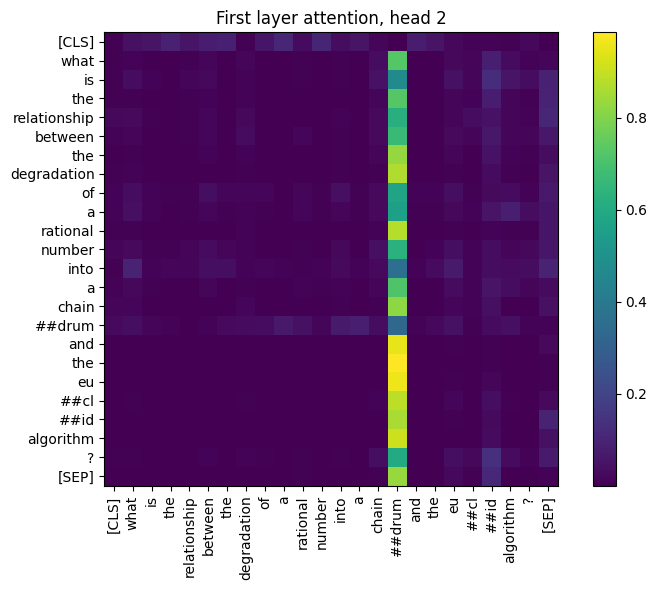

текст 2:
Two circles intersect at K and C points. Their centres are situated one side of the line containing the KC segments. The A and B points lie on different circles. A straight section containing the AK segment concerns one circle at K point. A straight section containing the BK segment touches the other circle also at K point. It is known that AK = 2, BK =, and tg\AKB = -. Find the area of the ABC triangle.


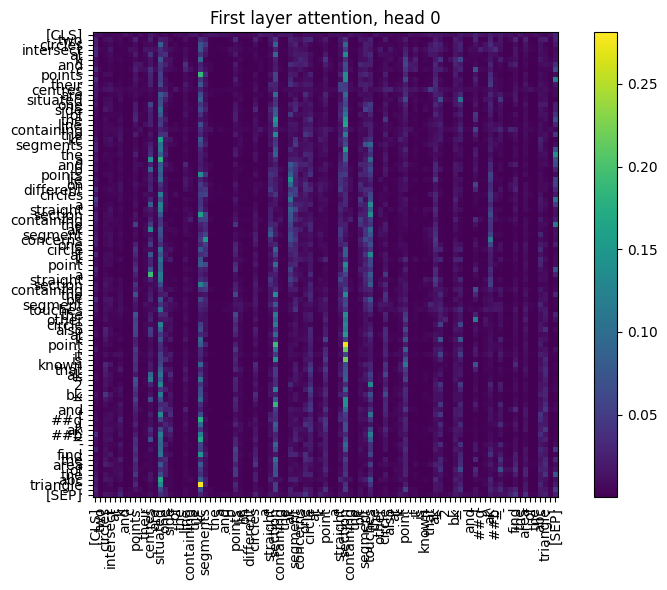

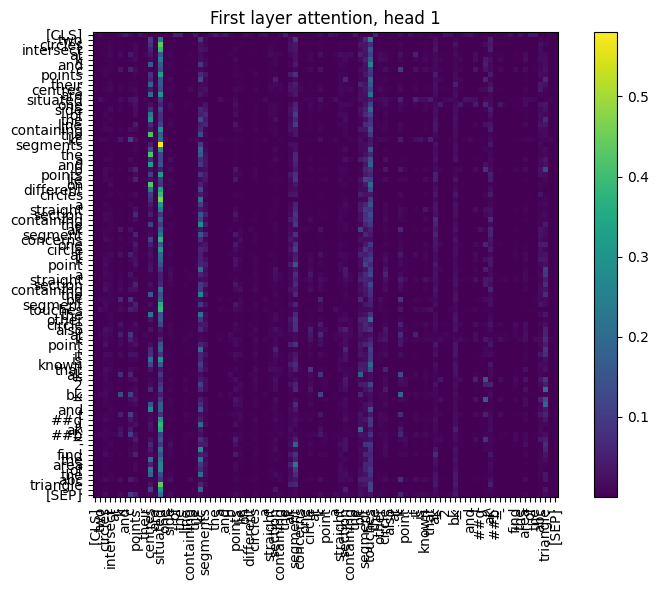

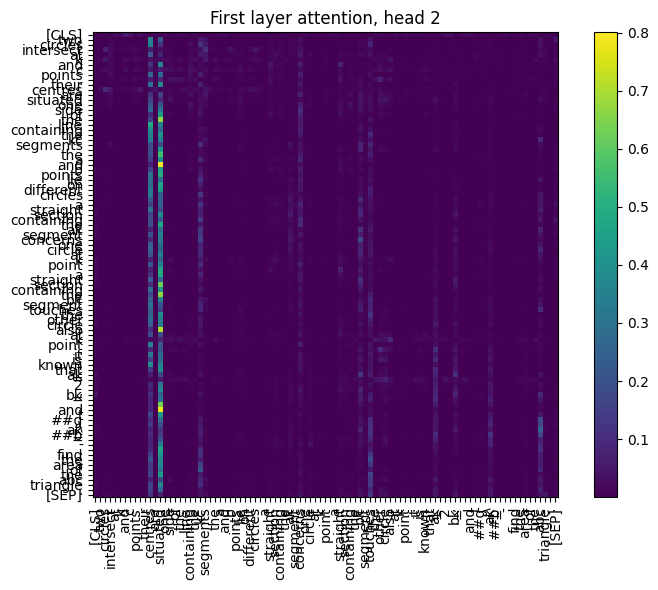

текст 3:
In Chicago, there are 36 criminal gangs, some of which are hostile to each other. Each gangster is in multiple gangs, and every two gangsters are in different gangs. It's known that no gangster is in two gangs, and it turns out that every gang that doesn't belong to a gangster is in conflict with some gang that this gangster is in. What's the largest number of gangsters in Chicago?


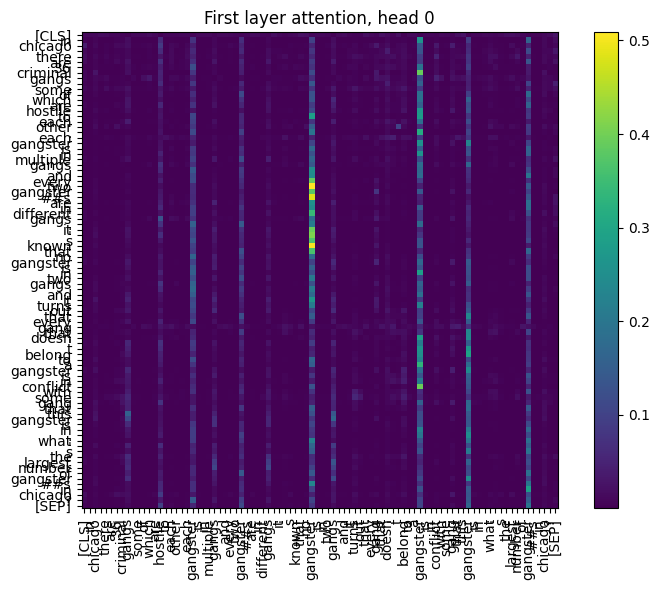

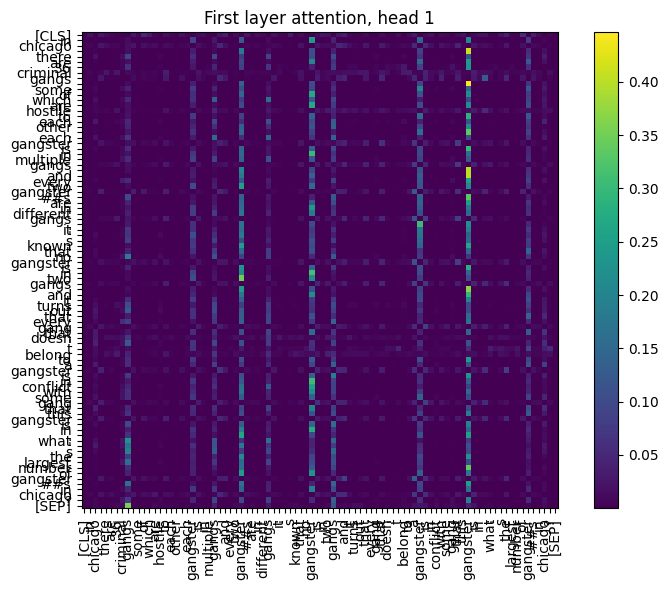

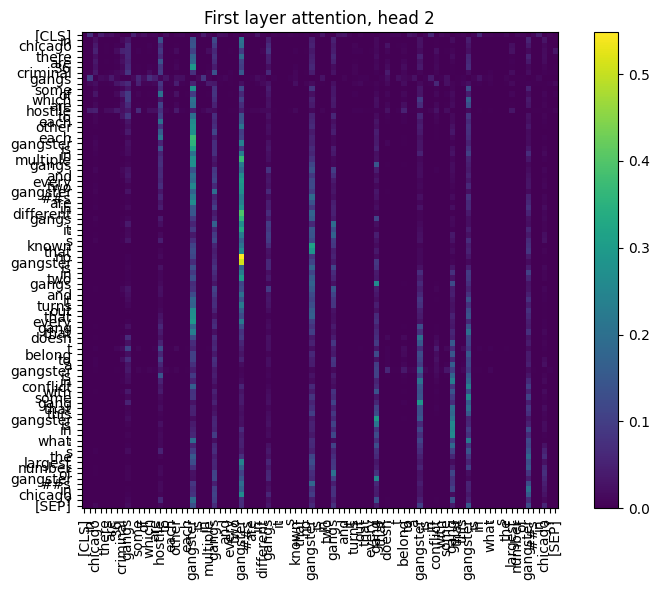

In [35]:
for i, text in enumerate(sample_texts_en, 1):
    print(f"текст {i}:")
    print(text)
    draw_first_layer_attention_maps(
        attention_head_ids=[0, 1, 2],
        text=text,
        model=mathbert_full,
        tokenizer=mathbert_tokenizer,
        device=device
    )

ну и здесь то же самое, никаких радикальных изменений не произошло, значит внутреннии представления адаптированись под датасет

# ВЫВОД

анализ карт внимания показал, что ruBERT и MathBERT даже до дообучения используют разные стратегии обработки текста в первом слое. у ruBERT сильнее выражены локальные зависимости, внимание к соседним токенам и к специальным токенам [CLS] и [SEP]. У MathBERT внимание чаще концентрируется на одной центральной позиции, что указывает на более глобальный и центрированный способ агрегации информации. После дообучения общая структура attention-карт изменилась незначительно у обеих моделей. предполагаю, улучшение качества классификации связано не с полной перестройкой первого слоя, а с более тонкой адаптацией уже существующих механизмов внимания и с изменениями в более глубоких слоях модели